# 02 · U2 MPPI — sampling, 비용 가중치, 분포 갱신

**한 줄 요약 (노션 U2):** 평균 행동열 주변의 후보를 sampling하고, 낮은 비용 후보에 높은 가중치를 주는 분포 갱신을 5회 반복한다.

### 학습 목표
1. cuRobo `ParallelMPPI`의 한 iteration(sample → rollout → cost → weight → 평균·분산 갱신)을 numpy로 직접 돌려 본다.
2. 후보 400개의 구성(380 + 10 + 10)과 마지막 0 노이즈를 코드로 확인한다.
3. `halton` / `halton-knot` 샘플과 `fixed_samples`의 의미를 그림으로 본다.
4. β, γ, `step_size_mean`, `step_size_cov`를 하나씩 바꿔 보며 역할을 구분한다.
5. `sample_mode: BEST`와 가중평균의 차이, 큰 soft cost의 의미를 확인한다.
6. 01 노트북의 벽 장면에서 gradient MPC가 못 찾은 우회로를 MPPI가 찾는지 본다.

### 노션 정리와의 연결
| 노션 U2 기록 | 이 노트 |
|---|---|
| 최적화 순서 1~6 | 1절 한 iteration 해부 |
| 후보 400 = 평균+noise 380 / 0 가속도 10 / −평균 10 | 1절, `particle_opt_base.py:286-289` |
| noise 하나를 0으로 고정 | `parallel_mppi.py:582` `s_set[:, :, -1] = 0` |
| halton 0.3 / halton-knot 0.7, fixed_samples | 2절 |
| $S_i=\sum\gamma^k c_{i,k}$, $w_i=\mathrm{softmax}(-S_i/\beta)$ | 3절 (실제 코드는 $\gamma^0$로 나눔) |
| $\mu_{new}=0.1\mu_{old}+0.9\sum w_i u_i$, $\Sigma_{new}=0.99\Sigma+0.01\Sigma_w+\kappa$ | 4절 (분산은 **갱신 전 평균** 기준) |
| BEST 출력 vs 가중평균 | 5절 |
| weight=100000 은 soft cost | 6절 |

토이 모델은 01과 같은 2D 점질량(`toy.PointMass2D`, 가속도 입력)이고, MPPI는 `toy.MPPI`에 cuRobo 항목 이름 그대로 구현했다.

In [1]:
import time
import numpy as np
from common import *
from toy import PointMass2D, Scene, MPPI, run_mppi, sample_noise, draw_scene
plt = setup_plot()

mppi_cfg = load_yaml(CUROBO / 'src/curobo/content/configs/task/particle_mpc.yml')['mppi']
for k in ['num_particles', 'n_iters', 'init_cov', 'gamma', 'beta', 'step_size_mean', 'step_size_cov',
          'kappa', 'null_act_frac', 'cov_type', 'sample_mode', 'squash_fn', 'base_action']:
    print(f'{k:15s} {mppi_cfg[k]}')
print('sample_params  ', mppi_cfg['sample_params'])

num_particles   400
n_iters         5
init_cov        0.05
gamma           0.98
beta            0.1
step_size_mean  0.9
step_size_cov   0.01
kappa           0.0001
null_act_frac   0.05
cov_type        DIAG_A
sample_mode     BEST
squash_fn       CLAMP
base_action     REPEAT
sample_params   {'fixed_samples': True, 'sample_ratio': {'halton': 0.3, 'halton-knot': 0.7, 'random': 0.0, 'random-knot': 0.0}, 'seed': 0, 'filter_coeffs': [0.3, 0.3, 0.4], 'n_knots': 5}


## 1. MPPI 한 iteration 해부

순서는 노션 U2의 "최적화 순서"와 같다.
1. 평균 행동열 $\mu$ (warm start: 직전 계획을 한 칸 shift한 값)
2. 후보 생성: $u^{(i)} = \mu + \epsilon^{(i)}\sqrt{\Sigma}$ 380개 + $-\mu$ 10개 + $0$ 10개 → CLAMP
3. 후보마다 rollout하고 시점별 비용 $c_{i,k}$ 계산 → `[400, N]`
4. $S_i$ → $w_i$
5. 평균·분산 갱신, 최고 가중치 후보를 `best`로 저장

먼저 후보 구성 수부터 확인한다. cuRobo 식(`particle_opt_base.py:286-289`)을 그대로 옮겼다.

noise 후보 380개, -평균 후보 10개, 0 후보 10개
null_per_problem = round(int(0.05*400*0.5)) = 10
neg_per_problem  = round(int(0.05*400)) - null = 10
마지막 noise가 0인가: True -> 후보 하나는 평균 그 자체
acts (400, 30, 2) | rollout P (400, 30, 2) | 총비용 S (400,)
best 후보 #258 (그룹: noise), w=0.713, S=14.47
-평균 후보 S 평균 94.6, 0 후보 S 평균 33.9, noise 후보 S 중앙값 53.7


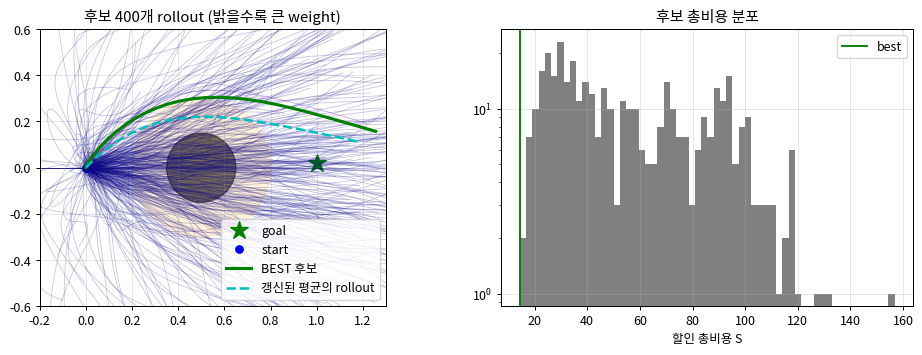

In [2]:
scene = Scene(goal=[1.0, 0.02], obstacles=[([0.5, 0.0], 0.15)])
model = PointMass2D(dt=0.05, horizon=30)
opt = MPPI(model, scene, num_particles=400, init_cov=1.0, beta=1.0)
print('noise 후보 %d개, -평균 후보 %d개, 0 후보 %d개' % (opt.noise_n, opt.neg_n, opt.null_n))
print('null_per_problem = round(int(0.05*400*0.5)) =', round(int(0.05 * 400 * 0.5)))
print('neg_per_problem  = round(int(0.05*400)) - null =', round(int(0.05 * 400)) - round(int(0.05 * 400 * 0.5)))
print('마지막 noise가 0인가:', np.allclose(opt.noise[-1], 0), '-> 후보 하나는 평균 그 자체')

# 시작 상태에서 평균을 '오른쪽으로 1 m/s^2' 정도로 두고 한 iteration
p0, v0 = np.zeros(2), np.zeros(2)
opt.mean[:] = [1.0, 0.0]
info = opt.iterate(p0, v0)
acts, P, S, w = info['acts'], info['P'], info['S'], info['w']
print('acts', acts.shape, '| rollout P', P.shape, '| 총비용 S', S.shape)
i_best = np.argmax(w)
print('best 후보 #%d (그룹: %s), w=%.3f, S=%.2f' % (i_best, 'noise' if i_best < opt.noise_n else ('-mean' if i_best < opt.noise_n + opt.neg_n else 'zero'), w[i_best], S[i_best]))
print('-평균 후보 S 평균 %.1f, 0 후보 S 평균 %.1f, noise 후보 S 중앙값 %.1f' % (
    S[opt.noise_n:opt.noise_n + opt.neg_n].mean(), S[-opt.null_n:].mean(), np.median(S[:opt.noise_n])))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
draw_scene(axs[0], scene, p0, lim=((-0.2, 1.3), (-0.6, 0.6)))
order = np.argsort(w)
for i in order:
    axs[0].plot(*P[i].T, color=plt.cm.plasma(min(1.0, w[i] / w.max())), lw=0.6, alpha=0.25 + 0.75 * w[i] / w.max())
axs[0].plot(*P[i_best].T, 'g-', lw=2.5, label='BEST 후보')
axs[0].plot(*model.rollout(p0, v0, opt.mean)[0].T, 'c--', lw=2, label='갱신된 평균의 rollout')
axs[0].legend(loc='lower right'); axs[0].set_title('후보 400개 rollout (밝을수록 큰 weight)')
axs[1].hist(S, bins=60, color='gray'); axs[1].set_yscale('log')
axs[1].axvline(S[i_best], color='g', label='best'); axs[1].set_xlabel('할인 총비용 S'); axs[1].legend()
axs[1].set_title('후보 총비용 분포')
plt.show()

- `-평균` 후보는 반대 방향으로 가속하므로 대부분 비싸다. 평균이 틀렸을 때 반대쪽을 확인하는 보험 역할이다.
- `0` 후보는 "가속하지 않음"이다. cuRobo는 가속도 제어이므로 **현재 속도를 유지**하는 후보가 된다(노션 표의 "현재 속도 유지 방향").
- 갱신된 평균(청록 점선)은 가중평균이라 BEST 후보와 다를 수 있다.

## 2. 샘플링 — halton vs halton-knot, fixed_samples

`sample_ratio: {'halton': 0.3, 'halton-knot': 0.7}`
- **halton**: 시점마다 독립인 준난수 가우시안. 행동열이 들쭉날쭉하다.
- **halton-knot**: `n_knots=5`개 점만 뽑고 B-spline으로 horizon 전체를 보간한다. 가속도 열이 매끄럽다.

준난수(Halton)는 같은 개수로 공간을 더 고르게 덮는다. `fixed_samples: True`면 이 노이즈 묶음을 한 번 만들어 **모든 iteration·모든 MPC step에서 재사용**한다 (`parallel_mppi.py:330-340`에서 `_sample_iter`를 올리지 않음). 조건 비교에서 sampling 변동을 없애 비용 변화의 효과만 보이게 하려는 설정이다.

샘플 평균 -0.004, 표준편차 0.989


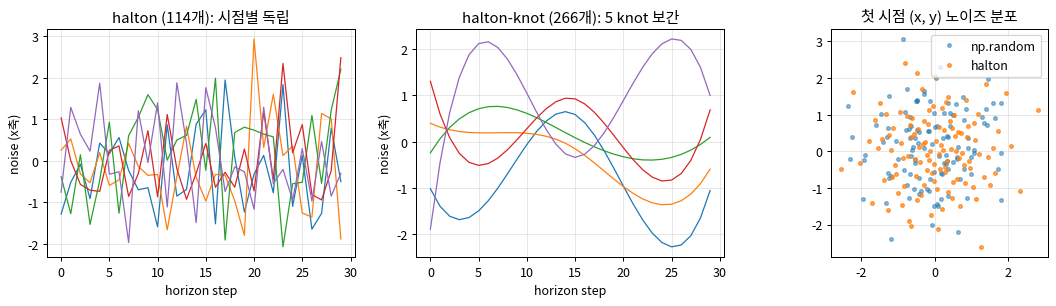

In [3]:
z = sample_noise(380, 30, 2, seed=0)
n_h = int(round(0.3 * 380))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.3))
t = np.arange(30)
for i in range(5):
    axs[0].plot(t, z[i, :, 0], lw=1)
    axs[1].plot(t, z[n_h + i, :, 0], lw=1)
axs[0].set_title('halton (%d개): 시점별 독립' % n_h); axs[1].set_title('halton-knot (%d개): 5 knot 보간' % (380 - n_h))
for a in axs[:2]:
    a.set_xlabel('horizon step'); a.set_ylabel('noise (x축)')
# 준난수 vs 의사난수: 2D 첫 시점 값 분포
rng = np.random.default_rng(0)
axs[2].plot(*rng.normal(size=(n_h, 2)).T, '.', alpha=0.5, label='np.random')
axs[2].plot(z[:n_h, 0, 0], z[:n_h, 0, 1], '.', alpha=0.7, label='halton')
axs[2].set_aspect('equal'); axs[2].legend(); axs[2].set_title('첫 시점 (x, y) 노이즈 분포')
plt.show()
print('샘플 평균 %.3f, 표준편차 %.3f' % (z.mean(), z.std()))

## 3. 비용 → weight: γ와 β

cuRobo 코드(`parallel_mppi.py:623-634`)는 다음을 계산한다.

$$
S_i = \frac{\sum_{k=0}^{N-1}\gamma^k c_{i,k}}{\gamma^0},\qquad w_i = \mathrm{softmax}\!\left(-\frac{S_i}{\beta}\right)
$$

$\gamma^0 = 1$이라 나눗셈은 사실상 의미가 없다. γ=0.98이면 마지막(k=29) 계수는 약 0.56으로, 먼 미래 비용을 덜 센다.

β는 **비용 차이를 weight 차이로 바꾸는 온도**다. weight 비는 $w_i/w_j = \exp(-(S_i-S_j)/\beta)$로 비용 차이에만 의존한다. 그래서 β의 크기는 후보 간 비용 차이와 비교해서 해석해야 한다. 집중도는 유효 샘플 수 $\mathrm{ESS} = 1/\sum w_i^2$로 잰다(1이면 한 후보에 몰림, 400이면 균등).

gamma^29 = 0.557, horizon 할인 계수 합 = 22.73 (할인 없으면 30)
ESS(S, beta=1) = 1.89 | ESS(10*S, beta=10) = 1.89 | ESS(10*S, beta=1) = 1.00
후보 비용: 최저 14.47, 하위 10% 24.67, 중앙값 53.69


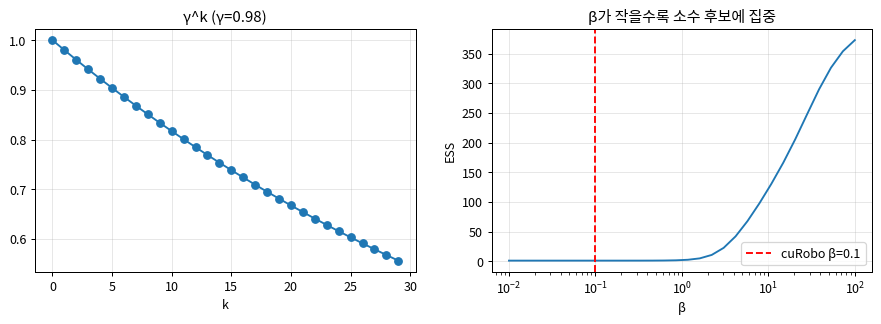

In [4]:
gamma_seq = 0.98 ** np.arange(30)
print('gamma^29 = %.3f, horizon 할인 계수 합 = %.2f (할인 없으면 30)' % (gamma_seq[-1], gamma_seq.sum()))

betas = np.logspace(-2, 2, 30)
ess = []
for b in betas:
    z_ = -(S - S.min()) / b
    ww = np.exp(z_); ww /= ww.sum()
    ess.append(1 / np.sum(ww ** 2))
ess = np.array(ess)

# 비용을 10배 하면 beta를 1/10로 한 것과 같다
def ess_of(Sv, b):
    z_ = -(Sv - Sv.min()) / b; ww = np.exp(z_); ww /= ww.sum(); return 1 / np.sum(ww ** 2)
print('ESS(S, beta=1) = %.2f | ESS(10*S, beta=10) = %.2f | ESS(10*S, beta=1) = %.2f' % (ess_of(S, 1), ess_of(10 * S, 10), ess_of(10 * S, 1)))
print('후보 비용: 최저 %.2f, 하위 10%% %.2f, 중앙값 %.2f' % (S.min(), np.percentile(S, 10), np.median(S)))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(np.arange(30), gamma_seq, 'o-'); axs[0].set_xlabel('k'); axs[0].set_title('γ^k (γ=0.98)')
axs[1].semilogx(betas, ess); axs[1].axvline(0.1, color='r', ls='--', label='cuRobo β=0.1')
axs[1].set_xlabel('β'); axs[1].set_ylabel('ESS'); axs[1].legend(); axs[1].set_title('β가 작을수록 소수 후보에 집중')
plt.show()

이 토이의 후보 비용 차이는 수 단위라서 β=0.1이면 거의 한 후보에 몰린다. 프로젝트에서도 06 노트북 로그 분석 결과, 손 근처 구간 대부분의 스텝에서 weight 절반 이상이 손 비용이 양수인 후보에 실렸다. 같은 β라도 비용 스케일(충돌 weight 100000 등)에 따라 집중도가 크게 달라진다.

## 4. 평균·분산 갱신 — step_size_mean과 step_size_cov

$$
\mu \leftarrow (1-0.9)\,\mu + 0.9\sum_i w_i u_i,\qquad
\Sigma \leftarrow (1-0.01)\,\Sigma + 0.01\,\underbrace{\mathrm{mean}_k\Big[\sum_i w_i (u_{i,k}-\mu_{old,k})^2\Big]}_{\text{DIAG\_A: 축별, horizon 평균}} + \kappa
$$

- 분산 갱신의 편차는 **갱신 전 평균** $\mu_{old}$ 기준이다 (`jit_mean_cov_diag_a`, `parallel_mppi.py:661-679`).
- `DIAG_A`: 관절(여기선 x, y축)마다 분산 하나. horizon 시점끼리는 공유한다.
- β는 weight의 집중도, `step_size_cov`는 탐색 폭이 줄어드는 속도다. 서로 다른 손잡이다(노션 6절 정정).

아래는 같은 장면에서 `step_size_cov`를 0.01(cuRobo)과 0.5로 바꿔 MPC를 돌리고 분산 변화를 비교한 것이다.

step_size_cov=0.01: 최종 목표 오차 0.036 m, 최소 간격 0.094 m, 마지막 분산 [0.4143 0.383 ]
step_size_cov=0.50: 최종 목표 오차 0.010 m, 최소 간격 0.087 m, 마지막 분산 [0.0028 0.0025]


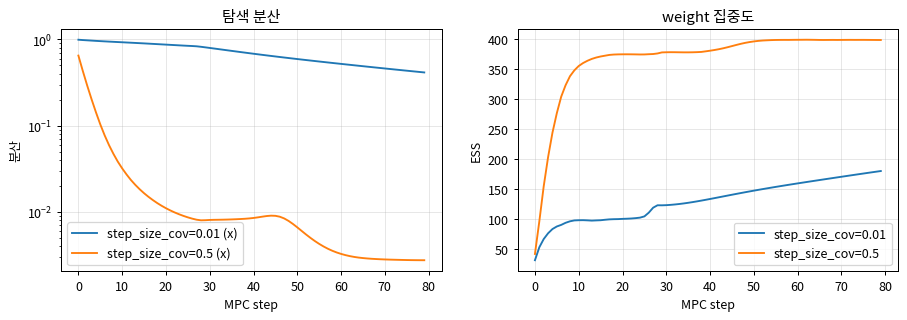

In [5]:
res = {}
for ssc in [0.01, 0.5]:
    tr, logs, _ = run_mppi(scene, steps=80, init_cov=1.0, beta=1.0, step_size_cov=ssc)
    res[ssc] = (tr, np.array([l['cov'][0] for l in logs]), np.array([l['ess'] for l in logs]))
    print('step_size_cov=%.2f: 최종 목표 오차 %.3f m, 최소 간격 %.3f m, 마지막 분산 %s' % (
        ssc, np.linalg.norm(tr[-1] - scene.goal), scene.gaps(tr).min(), res[ssc][1][-1].round(4)))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ssc, (tr, cov, ess_) in res.items():
    axs[0].plot(cov[:, 0], label=f'step_size_cov={ssc} (x)')
    axs[1].plot(ess_, label=f'step_size_cov={ssc}')
axs[0].set_yscale('log'); axs[0].set_xlabel('MPC step'); axs[0].set_ylabel('분산'); axs[0].legend(); axs[0].set_title('탐색 분산')
axs[1].set_xlabel('MPC step'); axs[1].set_ylabel('ESS'); axs[1].legend(); axs[1].set_title('weight 집중도')
plt.show()

이 정적 장면에서는 `step_size_cov=0.5`가 목표 근처에서 더 촘촘히 수렴해 최종 오차가 오히려 작다. 대신 분산이 수백 배 줄어 탐색 폭이 거의 사라졌다. 이 차이는 **다른 골짜기의 해가 필요한 장면**에서 드러난다. 7절의 벽 장면(N=40, init_cov=4)으로 같은 비교를 해 본다.

벽, step_size_cov=0.01: 최종 목표 오차 0.040 m, 마지막 분산 [[0.1809 0.1579]]
벽, step_size_cov=0.50: 최종 목표 오차 1.668 m, 마지막 분산 [[0.0065 0.0055]]


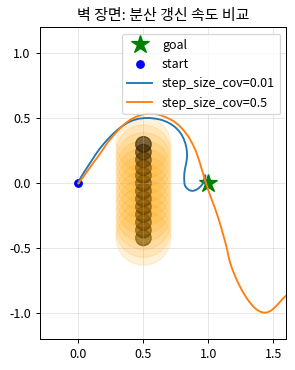

In [6]:
wall = [([0.5, y], 0.06) for y in np.arange(-0.42, 0.31, 0.06)]
wscene = Scene(goal=[1.0, 0.0], obstacles=wall)
fig, ax = plt.subplots(figsize=(6, 4.5))
draw_scene(ax, wscene, np.zeros(2), lim=((-0.3, 1.6), (-1.2, 1.2)))
for ssc in [0.01, 0.5]:
    tr, logs, _ = run_mppi(wscene, steps=200, horizon=40, init_cov=4.0, beta=1.0, step_size_cov=ssc)
    print('벽, step_size_cov=%.2f: 최종 목표 오차 %.3f m, 마지막 분산 %s' % (ssc, np.linalg.norm(tr[-1] - wscene.goal), logs[-1]['cov'].round(4)))
    ax.plot(*tr.T, label=f'step_size_cov={ssc}')
ax.legend(); ax.set_title('벽 장면: 분산 갱신 속도 비교'); plt.show()

분산이 빨리 줄면 한번 잘못 들어선 방향에서 빠져나올 탐색 폭이 남지 않는다. 손이 갑자기 나타나는 프로젝트 장면도 같은 상황이다. cuRobo가 평균은 빠르게(0.9), 분산은 천천히(0.01) 갱신하는 이유다. κ=1e-4는 분산이 0으로 붕괴하지 않게 하는 바닥값이다. 위 결과는 seed 하나의 토이 결과라서, 경향을 보는 용도로만 쓴다.

## 5. MPC 루프와 출력: BEST vs 가중평균

`sample_mode: BEST`면 실제 명령은 **가장 weight가 큰 단일 후보**(`best_traj`, `parallel_mppi.py:295-298`)이고, 가중평균은 다음 iteration의 분포 중심으로만 쓰인다. "MPPI 출력 = 가중평균"이라는 교과서 설명과 이 구현은 다르다.

BEST beta=0.1  목표 오차 0.173 m | 최소 간격 0.092 m | 가속도 변화량 평균 0.21 | 2.2s
BEST beta=1.0  목표 오차 0.036 m | 최소 간격 0.094 m | 가속도 변화량 평균 0.14 | 2.2s
MEAN beta=0.1  목표 오차 0.175 m | 최소 간격 0.091 m | 가속도 변화량 평균 0.21 | 2.2s
MEAN beta=1.0  목표 오차 0.032 m | 최소 간격 0.099 m | 가속도 변화량 평균 0.13 | 2.2s


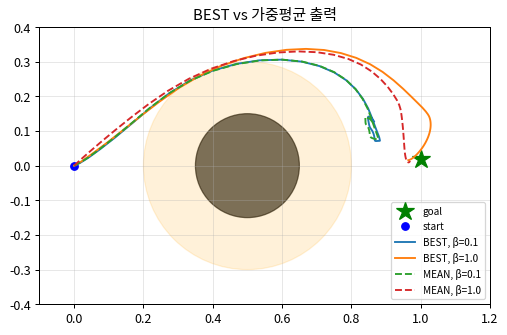

In [7]:
out = {}
for mode in ['BEST', 'MEAN']:
    for beta in [0.1, 1.0]:
        t0 = time.time()
        tr, logs, _ = run_mppi(scene, steps=80, init_cov=1.0, beta=beta, sample_mode=mode)
        out[(mode, beta)] = tr
        acc = np.diff(tr, 2, axis=0) / 0.05 ** 2
        print('%-4s beta=%-4s 목표 오차 %.3f m | 최소 간격 %.3f m | 가속도 변화량 평균 %.2f | %.1fs' % (
            mode, beta, np.linalg.norm(tr[-1] - scene.goal), scene.gaps(tr).min(), np.abs(np.diff(acc, axis=0)).mean(), time.time() - t0))

fig, ax = plt.subplots(figsize=(7, 4))
draw_scene(ax, scene, np.zeros(2), lim=((-0.1, 1.2), (-0.4, 0.4)))
for (mode, beta), tr in out.items():
    ax.plot(*tr.T, '-' if mode == 'BEST' else '--', label=f'{mode}, β={beta}')
ax.legend(fontsize=8, loc='lower right'); ax.set_title('BEST vs 가중평균 출력'); plt.show()

이 토이에서는 BEST와 MEAN의 궤적·매끄러움 차이가 작았고, β의 영향이 더 컸다(β=0.1은 소수 후보에 몰려 평균 갱신이 덜 안정적). 원리상 BEST는 단일 샘플이라 명령이 덜 매끄러울 수 있지만, 실제로 비용이 평가된 후보를 그대로 쓴다는 장점이 있다. 가중평균은 평가되지 않은 행동열이므로, 비용이 낮은 후보들이 서로 다른 골짜기(위로 우회 / 아래로 우회)에 나뉘어 있으면 평균이 그 사이(장애물 쪽)로 갈 수 있다.

## 6. 큰 soft cost — 모든 후보가 침범하면?

cuRobo의 충돌 weight 100000은 **후보를 지우는 hard constraint가 아니다**. 비용이 커질 뿐이고, softmax는 항상 합이 1이다. 그래서 모든 후보가 침범하면 그중 덜 나쁜 후보가 선택된다. 장애물 바로 앞에서 장애물 쪽으로 빠르게 움직이는 상태를 만들어 확인한다.

In [8]:
hard = Scene(goal=[1.0, 0.0], obstacles=[([0.5, 0.0], 0.15)], w_obs=1e5)
opt_h = MPPI(PointMass2D(dt=0.05, horizon=30), hard, init_cov=1.0, beta=0.1)
p_fast, v_fast = np.array([0.22, 0.0]), np.array([2.0, 0.0])   # 장애물 쪽으로 2 m/s
info = opt_h.iterate(p_fast, v_fast)
gap_min = hard.gaps(info['P']).min(axis=(1, 2))
print('침범하는 후보: %d / %d' % ((gap_min < 0).sum(), len(gap_min)))
print('weight 합 = %.6f, 최대 weight = %.4f' % (info['w'].sum(), info['w'].max()))
ib = np.argmax(info['w'])
print('선택 후보: 최소 간격 %.3f m, 총비용 %.3g (전체 최저 %.3g)' % (gap_min[ib], info['S'][ib], info['S'].min()))
dS = np.sort(info['S'])[:3] - info['S'].min()
print('하위 3개 비용 차이:', dS.round(1), '-> exp(-dS/0.1):', np.exp(-dS / 0.1))

침범하는 후보: 400 / 400
weight 합 = 1.000000, 최대 weight = 1.0000
선택 후보: 최소 간격 -0.148 m, 총비용 5.17e+04 (전체 최저 5.17e+04)
하위 3개 비용 차이: [   0.   897.1 1738.3] -> exp(-dS/0.1): [1. 0. 0.]


- 모든 후보가 침범해도 weight는 정규화되어 하나가 선택된다. 정지·안전 판단은 MPPI 밖의 별도 로직이 해야 한다.
- 비용 차이가 β보다 훨씬 크면 $e^{-\Delta S/\beta}$가 0으로 떨어져, 사실상 최저 비용 후보 하나만 남는다.
- 프로젝트에서 `feasible`은 관절 한계 등 제약 검사 결과이고 **손 비용은 포함되지 않는다** (05 노트북, `docs/diagnosis.md`). R 조건이 손 관측면과 겹친 스텝에서도 feasible=True였다(06 노트북).

## 7. 01의 벽 장면 다시: gradient MPC vs MPPI

01에서 gradient 기반 MPC는 horizon을 80까지 늘려도 벽 앞에서 멈췄다. 같은 벽을 MPPI로 푼다. horizon과 초기 분산(탐색 폭)을 바꿔 본다.

N=10 (0.5 s) init_cov=1: 목표 오차 0.710 m, 최소 간격 0.094 m, 최대 y 0.05 -> 벽 앞 정체
N=10 (0.5 s) init_cov=4: 목표 오차 0.707 m, 최소 간격 0.094 m, 최대 y 0.08 -> 벽 앞 정체
N=20 (1.0 s) init_cov=1: 목표 오차 0.708 m, 최소 간격 0.093 m, 최대 y 0.10 -> 벽 앞 정체
N=20 (1.0 s) init_cov=4: 목표 오차 0.039 m, 최소 간격 0.091 m, 최대 y 0.51 -> 우회 성공
N=40 (2.0 s) init_cov=1: 목표 오차 0.714 m, 최소 간격 0.104 m, 최대 y 0.09 -> 벽 앞 정체
N=40 (2.0 s) init_cov=4: 목표 오차 0.040 m, 최소 간격 0.091 m, 최대 y 0.50 -> 우회 성공
N=60 (3.0 s) init_cov=1: 목표 오차 0.007 m, 최소 간격 0.077 m, 최대 y 0.50 -> 우회 성공
N=60 (3.0 s) init_cov=4: 목표 오차 0.047 m, 최소 간격 0.075 m, 최대 y 0.49 -> 우회 성공


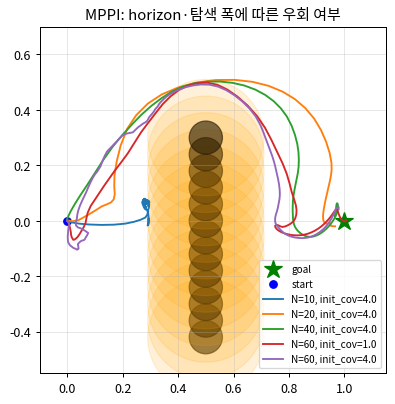

In [9]:
rows, trajs = [], {}
for N in [10, 20, 40, 60]:
    for ic in [1.0, 4.0]:
        tr, logs, _ = run_mppi(wscene, steps=200, horizon=N, init_cov=ic, beta=1.0)
        trajs[(N, ic)] = tr
        err = np.linalg.norm(tr[-1] - wscene.goal)
        rows.append((N, ic, err, wscene.gaps(tr).min(), tr[:, 1].max()))
        print('N=%2d (%.1f s) init_cov=%.0f: 목표 오차 %.3f m, 최소 간격 %.3f m, 최대 y %.2f -> %s' % (
            N, N * 0.05, ic, err, rows[-1][3], rows[-1][4], '우회 성공' if err < 0.1 else '벽 앞 정체'))

fig, ax = plt.subplots(figsize=(7, 5))
draw_scene(ax, wscene, np.zeros(2), lim=((-0.1, 1.15), (-0.55, 0.7)))
for (N, ic), tr in trajs.items():
    if ic == 4.0 or N == 60:
        ax.plot(*tr.T, label=f'N={N}, init_cov={ic}')
ax.legend(fontsize=8); ax.set_title('MPPI: horizon·탐색 폭에 따른 우회 여부'); plt.show()

**해석**
- N=10(0.5 s)은 탐색 폭을 키워도 정체한다. 01 5절에서 본 것처럼 짧은 horizon에서는 우회 후보가 정지보다 비싸기 때문이다. 샘플링으로 우회 후보를 **찾아도** 선택되지 않는다.
- horizon이 우회 이득을 볼 만큼 길면, 넓게 뿌린 샘플이 다른 골짜기(위쪽 우회)의 후보를 평가해 그쪽으로 옮겨 간다. 탐색 폭(init_cov)이 작으면 더 긴 horizon이 필요했다.
- 그래도 이것은 seed 하나, 장면 하나의 결과다. 샘플링 기반이 local minimum을 **보장해서** 피하는 것은 아니다.

프로젝트 설정(horizon 0.675 s, init_cov 0.05, 400 후보, β=0.1)에서는 손이 경로를 완전히 막는 장면이 아니라 위로 비켜 가는 경로가 있었다. 07 노트북의 Isaac Sim 실습에서는 장애물 앞 정체가 실제로 관찰됐다.

## 8. 실제 코드 연결 — cuRobo `ParallelMPPI`

| 단계 | 위치 (`~/curobo/src/curobo/`) |
|---|---|
| shift 후 평균 = init_act, 5회 반복 | `opt/particle/particle_opt_base.py:251-258` `_run_opt_iters` (로컬 파일에 한글 주석이 있음) |
| null / neg 후보 수 | `particle_opt_base.py:286-289` |
| 후보 생성 (mean + noise·√cov, −mean, 0, CLAMP) | `opt/particle/parallel_mppi.py:329-363` `sample_actions` |
| 마지막 noise = 0 | `parallel_mppi.py:582` |
| BEST 저장, 평균·분산 갱신 | `parallel_mppi.py:284-327` `_update_distribution` |
| 할인 합, softmax, blend | `parallel_mppi.py:617-679` |

In [10]:
src = CUROBO / 'src/curobo/opt/particle/parallel_mppi.py'
show_code(src, 292, 298)
print('...')
show_code(src, 341, 362)
print('...')
show_code(src, 650, 658)
print('...')
show_code(CUROBO / 'src/curobo/opt/particle/particle_opt_base.py', 284, 290)

  292|         with profiler.record_function("mppi/get_best"):
  293| 
  294|             # Update best action
  295|             if self.sample_mode == SampleMode.BEST:
  296|                 w = self._exp_util_from_costs(costs)
  297|                 best_idx = torch.argmax(w, dim=-1)
  298|                 self.best_traj.copy_(actions[self.problem_col, best_idx])
...
  341|         act_seq = self.mean_action.unsqueeze(-3) + scaled_delta
  342|         cat_list = [act_seq]
  343| 
  344|         if self.neg_per_problem > 0:
  345|             neg_action = -1.0 * self.mean_action
  346|             neg_act_seqs = neg_action.unsqueeze(-3).expand(-1, self.neg_per_problem, -1, -1)
  347|             cat_list.append(neg_act_seqs)
  348|         if self.null_per_problem > 0:
  349|             cat_list.append(
  350|                 self.null_act_seqs[: self.null_per_problem]
  351|                 .unsqueeze(0)
  352|                 .expand(self.n_problems, -1, -1, -1)
  353|            

## 정정 포인트

| 이전 이해 | 정정 |
|---|---|
| 큰 ROI 비용이면 후보 제거 | soft cost 증가 → weight가 매우 작아질 뿐. 모든 후보가 비싸면 덜 나쁜 후보 선택 (6절) |
| 최종 출력은 가중평균 | `sample_mode: BEST` → 최고 weight 단일 후보. 가중평균은 분포 갱신용 (5절) |
| 분산 갱신을 느리게 하면 β가 줄어드는 효과 | 독립 손잡이: β = weight 집중도, step_size_cov = 탐색 폭 감소 속도 (4절) |
| 분산은 새 평균 기준 편차 | **갱신 전 평균** 기준 (`jit_mean_cov_diag_a`) |
| 0 가속도 후보 = 정지 | 가속도 0 = **현재 속도 유지** |
| 샘플링이면 local minimum을 피한다 | horizon이 짧아 우회가 비싸면 찾아도 선택되지 않음 (7절) |

## 복습 질문

<details><summary>1. β를 0.1에서 1로 키우면 같은 장면에서 무엇이 바뀌는가?</summary>
비용 차이 대비 온도가 높아져 weight가 여러 후보로 퍼진다(ESS 증가). 평균 갱신이 더 많은 후보의 평균이 되어 매끄러워지지만, 최저 비용 후보 쪽으로 덜 빠르게 움직인다. BEST 선택(argmax)은 β와 무관하게 같은 후보다.
</details>

<details><summary>2. fixed_samples=True가 조건 비교(R/LOW/HIGH)에 유리한 이유와 한계는?</summary>
같은 노이즈 묶음을 쓰므로 조건 간 차이가 sampling 우연이 아니라 비용 차이에서 온다고 해석하기 쉽다. 하지만 평균이 바뀌면 실제 후보도 바뀌고, 하나의 노이즈 묶음에 대한 결과일 뿐이다. 여러 seed 반복이 따로 필요하다.
</details>

<details><summary>3. -평균 후보와 0 후보는 각각 어떤 상황에서 BEST가 될 수 있는가?</summary>
-평균: 직전 계획 방향이 갑자기 나빠졌을 때(예: 진행 방향에 장애물 등장). 0: 현재 속도를 유지하는 것이 가장 좋을 때(목표 근처, 이미 좋은 속도).
</details>

<details><summary>4. 모든 후보가 손 ROI를 침범하면 cuRobo는 무엇을 출력하는가?</summary>
softmax 정규화로 가장 덜 나쁜 후보가 BEST가 되어 그대로 출력된다. 손 비용은 feasible에 포함되지 않으므로 hold-measured도 작동하지 않는다. 안전 정지는 별도 로직이 필요하다.
</details>

**다음:** [03 · U3 cuRobo rollout](03_U3_curobo_rollout.ipynb) — 점질량 대신 Franka 7관절: 가변 dt horizon, 가속도 적분, FK와 61개 충돌 구, η 비용식.